# Gathering Features and Clustering

## Research question

What structural kinds of gathering episodes appear in the student interaction network?

The analysis constructs one feature vector per episode from size, span, membership expansion, Bluetooth signal strength, recorded friendship links, and prior communication. The analysis compares K-Means representations, inspect cluster profiles, and distinguish initialization stability from feature sensitivity.

**Scope:** this is retrospective, descriptive analysis. The clusters are not verified lectures, parties, or study sessions, and Bluetooth proximity is not proof of social interaction.

## Notebook guide

- Build and validate the episode feature table.
- Compare structural and social/communication representations.
- Evaluate cluster counts, profiles, initialization stability, and feature sensitivity.
- Export a coarse two-cluster partition and an exploratory five-cluster partition.
- Visualize with PCA and check saved artifacts.

## Required configuration

The shared configuration must contain the following additional sections. Existing extraction settings should remain unchanged.

```yaml
feature_parameters:
  communication_lookback_hours: 24
archetype_clustering_parameters:
  random_seed: 42
  k_values: [2, 3, 4, 5, 6, 7, 8]
  n_init: 20
  silhouette_sample_size: 3000
  coarse_k: 2
  descriptive_k: 5
cluster_stability_parameters:
  seeds: [1, 2, 3, 4, 5]
```

The shared processed inputs must already exist. This copy has saved outputs cleared; run it top to bottom to regenerate tables and figures. A clean-kernel execution has not been verified as part of this editorial revision.


## Inputs and setup

The analysis starts from the shared episode and slot-level gathering tables. The analysis uses the project configuration for paths and extraction settings, rather than defining a separate version of the pipeline.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import yaml

# Locate the shared config from either the root or notebooks folder.
ROOT = Path.cwd().resolve()

while not (ROOT / "config" / "config.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Could not find the project root.")
    ROOT = ROOT.parent

with (ROOT / "config" / "config.yaml").open() as file:
    config = yaml.safe_load(file)

processed_dir = ROOT / config["paths"]["processed_data_dir"]
slot_seconds = config["time_parameters"]["slot_duration_sec"]

episodes = pd.read_parquet(processed_dir / "episodes_v1.parquet")
gatherings = pd.read_parquet(processed_dir / "gatherings_v1.parquet")

print("Episodes:", episodes.shape)
print("Slot-level gatherings:", gatherings.shape)
print("Slot length:", slot_seconds, "seconds")

Episodes: (22530, 13)
Slot-level gatherings: (98194, 6)
Slot length: 300 seconds


## Input consistency checks

Before building features, The checks cover episode IDs, slot spans, missing slots, and links to the gathering table. These checks test the internal consistency of the hand-off, not whether a detected episode represents a real social event.


In [2]:
# Check the episode links before calculating anything from them.
assert episodes["episode_id"].is_unique
assert gatherings["gathering_id"].is_unique

assert (episodes["n_slots"] >= 1).all()
assert (episodes["n_gap_slots"] >= 0).all()
assert (episodes["n_gap_slots"] < episodes["n_slots"]).all()

assert (
    episodes["n_slots"]
    == episodes["last_slot"] - episodes["first_slot"] + 1
).all()

assert (
    episodes["end_time"] - episodes["start_time"]
    == (episodes["n_slots"] - 1) * slot_seconds
).all()

assert (
    episodes["gathering_ids"].map(len)
    == episodes["n_slots"] - episodes["n_gap_slots"]
).all()

linked_ids = episodes["gathering_ids"].explode()

assert linked_ids.isin(gatherings["gathering_id"]).all()
assert not linked_ids.duplicated().any()

print("Episode consistency checks passed.")

Episode consistency checks passed.


## Episode-level features

A distinction is made between typical simultaneous group size from the union of participants across an episode. Span includes missing slots; observed minutes count only slots with a gathering row. Both are bin-based summaries, not precise continuous interaction durations. Membership expansion is descriptive and is not a turnover rate.


In [3]:
# Keep one row per episode and preserve the original metadata.
features = episodes.copy()

features["n_unique_participants"] = features["participant_set"].map(
    lambda members: len(set(members))
)

features["n_observed_slots"] = (
    features["n_slots"] - features["n_gap_slots"]
)

# Treat every covered slot as a five-minute bin.
# A one-slot episode therefore has a five-minute bin span, not zero.
features["span_minutes"] = (
    features["n_slots"] * slot_seconds / 60
)

features["observed_minutes"] = (
    features["n_observed_slots"] * slot_seconds / 60
)

features["gap_fraction"] = (
    features["n_gap_slots"] / features["n_slots"]
)

# Compare the membership union with the typical simultaneous group size.
# This is a descriptive membership-expansion measure, not a turnover rate.
features["membership_expansion_ratio"] = (
    features["n_unique_participants"] / features["median_size"]
)

# Keep relative time as relative time; do not invent calendar dates.
features["relative_day_index"] = (
    features["start_time"] // 86400
).astype(int)

features["log_median_size"] = np.log1p(features["median_size"])
features["log_span_minutes"] = np.log1p(features["span_minutes"])

# Record which shared extraction settings produced these features.
features["input_version"] = "episodes_v1"
features["feature_version"] = "baseline_v1"
features["rssi_threshold"] = config["bluetooth_parameters"]["rssi_threshold"]
features["episode_jaccard_threshold"] = (
    config["episode_parameters"]["jaccard_threshold"]
)
features["episode_max_gap_slots"] = (
    config["episode_parameters"]["max_gap_slots"]
)

## Baseline feature table

The analysis retains a compact structural baseline and save an intermediate feature table. Log transforms reduce the influence of the long upper tails in size and span. Identifiers and metadata remain available for tracing results but are not clustering inputs.


In [4]:
# Start with a compact feature set instead of repeating size and duration
# through several highly related columns.
baseline_columns = [
    "log_median_size",
    "log_span_minutes",
    "gap_fraction",
    "membership_expansion_ratio",
    "median_rssi",
]

X = features[baseline_columns].astype(float)

assert features["episode_id"].is_unique
assert len(features) == len(episodes)
assert np.isfinite(X.to_numpy()).all()
assert features["gap_fraction"].between(0, 1).all()
assert (features["span_minutes"] > 0).all()
assert (
    features["observed_minutes"] <= features["span_minutes"]
).all()

# Use a baseline filename so this is not mistaken for the final feature table.
output_path = processed_dir / "gathering_features_baseline_v1.parquet"
features.to_parquet(output_path, index=False)

print("Saved:", output_path)
print("Feature-table shape:", features.shape)
print("\nBaseline feature summary:")
print(X.describe().T.to_string())

Saved: /home/manolis/Desktop/uni/DataMining/UU-DataMining-2026/data/processed/gathering_features_baseline_v1.parquet
Feature-table shape: (22530, 27)

Baseline feature summary:
                              count       mean       std        min        25%        50%        75%        max
log_median_size             22530.0   1.798257  0.617867   1.386294   1.386294   1.609438   1.945910   5.159055
log_span_minutes            22530.0   2.494653  0.973561   1.791759   1.791759   1.791759   3.044522   6.825460
gap_fraction                22530.0   0.037251  0.090489   0.000000   0.000000   0.000000   0.000000   0.454545
membership_expansion_ratio  22530.0   1.058204  0.143030   1.000000   1.000000   1.000000   1.000000   3.360000
median_rssi                 22530.0 -81.208156  5.159852 -90.000000 -85.000000 -82.000000 -78.500000 -48.000000


## Secondary data

The analysis reuses the shared loaders for Facebook, calls, and SMS. The analysis leaves gender out of the clustering representation. All timestamps remain relative seconds; The analysis does not introduce calendar dates or weekdays.


In [5]:
import sys

# Reuse the project's loaders instead of writing another CSV parser.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.io import load_facebook_data, load_telecom_data

raw_dir = ROOT / config["paths"]["raw_data_dir"]

friends = load_facebook_data(raw_dir / "fb_friends.csv")
calls = load_telecom_data(raw_dir / "calls.csv", log_type="calls")
sms = load_telecom_data(raw_dir / "sms.csv", log_type="sms")

assert {"user_a", "user_b"}.issubset(friends.columns)
assert {"timestamp", "caller", "callee", "duration"}.issubset(calls.columns)
assert {"timestamp", "sender", "recipient"}.issubset(sms.columns)

print("Facebook:", friends.shape)
print("Calls:", calls.shape)
print("SMS:", sms.shape)

print("\nCall timestamp range:", calls["timestamp"].min(), calls["timestamp"].max())
print("SMS timestamp range:", sms["timestamp"].min(), sms["timestamp"].max())

Facebook: (6429, 2)
Calls: (3600, 5)
SMS: (24333, 3)

Call timestamp range: 184 2416399
SMS timestamp range: 18 2418982


## Recorded friendship density

The analysis treats Facebook links as undirected and count each pair once. Density is computed over the episode membership union, whose members need not all be present simultaneously. An absent link means no recorded friendship, not necessarily no social relationship. The friendship snapshot is retrospective and is not a leakage-free forecasting input.


In [6]:
# Store each friendship once, regardless of which direction it appears in.
fb = friends[["user_a", "user_b"]].dropna().copy()

fb["user_a"] = fb["user_a"].astype(int)
fb["user_b"] = fb["user_b"].astype(int)

fb = fb[
    (fb["user_a"] >= 0)
    & (fb["user_b"] >= 0)
    & (fb["user_a"] != fb["user_b"])
]

friend_pairs = {
    tuple(sorted((a, b)))
    for a, b in fb.itertuples(index=False, name=None)
}

# An adjacency lookup avoids generating every possible member pair.
friend_neighbors = {}

for a, b in friend_pairs:
    friend_neighbors.setdefault(a, set()).add(b)
    friend_neighbors.setdefault(b, set()).add(a)


def friendship_summary(members):
    members = set(map(int, members))
    possible_pairs = len(members) * (len(members) - 1) // 2

    # Every internal friendship is counted at both endpoints.
    n_edges = sum(
        len(friend_neighbors.get(member, set()) & members)
        for member in members
    ) // 2

    density = n_edges / possible_pairs if possible_pairs else 0.0
    return n_edges, density


friendship_values = [
    friendship_summary(members)
    for members in features["participant_set"]
]

features["internal_fb_edges"] = [value[0] for value in friendship_values]
features["internal_fb_density"] = [value[1] for value in friendship_values]

assert features["internal_fb_density"].between(0, 1).all()

print(
    features[["internal_fb_edges", "internal_fb_density"]]
    .describe()
    .to_string()
)

       internal_fb_edges  internal_fb_density
count       22530.000000         22530.000000
mean            7.442921             0.265554
std            21.387384             0.272648
min             0.000000             0.000000
25%             1.000000             0.043104
50%             2.000000             0.200000
75%             4.000000             0.333333
max           408.000000             1.000000


## Communication window

The analysis uses communication between episode members in the 24 hours before the episode starts. The window is left-inclusive and right-exclusive, so events at the start time are excluded. The lookback is controlled by the shared configuration.


In [7]:
# Read the communication settings from the shared config.
with (ROOT / "config" / "config.yaml").open() as file:
    config = yaml.safe_load(file)

lookback_hours = config["feature_parameters"]["communication_lookback_hours"]
lookback_seconds = int(lookback_hours * 3600)

assert lookback_seconds > 0

## Prior communication features

The implementation sorts each event table once and locate time windows with binary searches. The implementation counts only events with both endpoints in the membership union, and separate missed calls from non-missed calls. Early episodes have incomplete recorded history; zero counts there must not be interpreted as evidence of no communication.


In [8]:
def prepare_events(table, left_column, right_column):
    events = table[["timestamp", left_column, right_column]].copy()

    # Fail explicitly if the input contains invalid numeric values.
    for column in events.columns:
        events[column] = pd.to_numeric(events[column], errors="raise")

    assert events.notna().all().all()
    assert (events["timestamp"] >= 0).all()

    events = events[
        (events[left_column] >= 0)
        & (events[right_column] >= 0)
        & (events[left_column] != events[right_column])
    ]

    return events.sort_values("timestamp").reset_index(drop=True)


def communication_summary(events, left_column, right_column, prefix):
    times = events["timestamp"].to_numpy()
    left_ids = events[left_column].to_numpy(dtype=int)
    right_ids = events[right_column].to_numpy(dtype=int)

    records = []

    for episode in features.itertuples(index=False):
        start = int(episode.start_time)
        members = np.asarray(episode.participant_set, dtype=int)

        # Use [start - lookback, start), bounded by the dataset origin.
        window_start = max(0, start - lookback_seconds)
        lower = np.searchsorted(times, window_start, side="left")
        upper = np.searchsorted(times, start, side="left")

        a = left_ids[lower:upper]
        b = right_ids[lower:upper]

        internal = np.isin(a, members) & np.isin(b, members)
        a = a[internal]
        b = b[internal]

        # Ignore direction for the active-pair summary, not the event count.
        active_pairs = {
            tuple(sorted((int(user_a), int(user_b))))
            for user_a, user_b in zip(a, b)
        }

        records.append({
            "episode_id": episode.episode_id,
            f"{prefix}_events_pre": len(a),
            f"{prefix}_active_pairs_pre": len(active_pairs),
        })

    return pd.DataFrame(records)


# Separate missed calls from completed/non-missed call records.
durations = pd.to_numeric(calls["duration"], errors="raise")
assert durations.notna().all()
assert ((durations == -1) | (durations >= 0)).all()

completed_calls = prepare_events(
    calls.loc[durations >= 0], "caller", "callee"
)
missed_calls = prepare_events(
    calls.loc[durations == -1], "caller", "callee"
)
sms_events = prepare_events(sms, "sender", "recipient")

communication_tables = [
    communication_summary(completed_calls, "caller", "callee", "calls"),
    communication_summary(missed_calls, "caller", "callee", "missed_calls"),
    communication_summary(sms_events, "sender", "recipient", "sms"),
]

# Replace these columns if this cell is rerun.
for table in communication_tables:
    new_columns = table.columns.difference(["episode_id"])
    features = features.drop(columns=new_columns, errors="ignore")

    features = features.merge(
        table,
        on="episode_id",
        how="left",
        validate="one_to_one",
    )

print("Communication features added.")

Communication features added.


## Feature validation and export

The analysis records how much pre-episode history is available, validate the event counts, and save the extended feature table. The full table retains early episodes even though they are excluded from the first communication-based clustering fits.


In [9]:
features["prehistory_available_hours"] = (
    features["start_time"].clip(lower=0, upper=lookback_seconds) / 3600
)

features["has_full_communication_window"] = (
    features["start_time"] >= lookback_seconds
)

features["communication_lookback_hours"] = lookback_hours

for prefix in ["calls", "missed_calls", "sms"]:
    count_column = f"{prefix}_events_pre"
    pair_column = f"{prefix}_active_pairs_pre"

    assert features[count_column].notna().all()
    assert (features[count_column] >= 0).all()
    assert (features[pair_column] <= features[count_column]).all()

    features[f"log_{count_column}"] = np.log1p(features[count_column])

features["feature_version"] = "social_communication_v1"

assert len(features) == len(episodes)
assert features["episode_id"].is_unique

summary_columns = [
    "median_size",
    "span_minutes",
    "internal_fb_density",
    "calls_events_pre",
    "missed_calls_events_pre",
    "sms_events_pre",
    "prehistory_available_hours",
]

print(features[summary_columns].describe().T.to_string())
print(
    "\nEpisodes with a full communication window:",
    int(features["has_full_communication_window"].sum()),
)

# Keep this separate from the earlier baseline output.
output_path = processed_dir / "gathering_features_v1.parquet"
features.to_parquet(output_path, index=False)

print("\nSaved:", output_path)
print("Shape:", features.shape)

                              count       mean        std  min        25%   50%        75%    max
median_size                 22530.0   7.065091  10.262988  3.0   3.000000   4.0   6.000000  173.0
span_minutes                22530.0  23.268531  50.576772  5.0   5.000000   5.0  20.000000  920.0
internal_fb_density         22530.0   0.265554   0.272648  0.0   0.043104   0.2   0.333333    1.0
calls_events_pre            22530.0   0.555304   1.686905  0.0   0.000000   0.0   0.000000   50.0
missed_calls_events_pre     22530.0   0.047847   0.311099  0.0   0.000000   0.0   0.000000    9.0
sms_events_pre              22530.0   4.240169  17.426497  0.0   0.000000   0.0   1.000000  422.0
prehistory_available_hours  22530.0  23.869256   1.435845  0.0  24.000000  24.0  24.000000   24.0

Episodes with a full communication window: 22259

Saved: /home/manolis/Desktop/uni/DataMining/UU-DataMining-2026/data/processed/gathering_features_v1.parquet
Shape: (22530, 41)


## Initial clustering design

The analysis compares a structural representation with a social/communication extension on the same eligible episodes. The analysis retains single-slot episodes and exclude unverified clock-hour flags. The analysis excludes IDs, anomaly labels, or duplicate raw and log representations of the same measurement.


In [10]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

with (ROOT / "config" / "config.yaml").open() as file:
    config = yaml.safe_load(file)

settings = config["archetype_clustering_parameters"]
coarse_k = int(settings["coarse_k"])
descriptive_k = int(settings["descriptive_k"])
assert coarse_k in settings["k_values"]
assert descriptive_k in settings["k_values"]

# Use equal communication-history coverage for the initial comparison.
eligible = features.loc[
    features["has_full_communication_window"]
].copy().reset_index(drop=True)

feature_sets = {
    "structural": [
        "log_median_size",
        "log_span_minutes",
        "gap_fraction",
        "membership_expansion_ratio",
        "median_rssi",
    ],
    "social_communication": [
        "log_median_size",
        "log_span_minutes",
        "gap_fraction",
        "membership_expansion_ratio",
        "median_rssi",
        "internal_fb_density",
        "log_calls_events_pre",
        "log_sms_events_pre",
    ],
}

print("Episodes used:", len(eligible))
print("Episodes excluded for incomplete history:", len(features) - len(eligible))

Episodes used: 22259
Episodes excluded for incomplete history: 271


## Scaling

The preprocessing standardizes each representation independently and remove constant columns. This defines the Euclidean distance used by K-Means. Adding or removing features changes that geometry, so scores across representations are not a direct ranking of scientific usefulness.


In [11]:
scaled_data = {}
scalers = {}
used_columns = {}

for representation, columns in feature_sets.items():
    X = eligible[columns].astype(float)

    assert np.isfinite(X.to_numpy()).all()

    # Constant features cannot help distinguish episodes.
    constant_columns = X.columns[X.nunique() <= 1].tolist()
    X = X.drop(columns=constant_columns)

    scaler = StandardScaler()
    scaled_data[representation] = scaler.fit_transform(X)
    scalers[representation] = scaler
    used_columns[representation] = X.columns.tolist()

    print(f"\n{representation}")
    print("Features:", used_columns[representation])
    print("Constant features removed:", constant_columns)


structural
Features: ['log_median_size', 'log_span_minutes', 'gap_fraction', 'membership_expansion_ratio', 'median_rssi']
Constant features removed: []

social_communication
Features: ['log_median_size', 'log_span_minutes', 'gap_fraction', 'membership_expansion_ratio', 'median_rssi', 'internal_fb_density', 'log_calls_events_pre', 'log_sms_events_pre']
Constant features removed: []


## Initial cluster-count comparison

The analysis compares two to eight clusters with a fixed seed and multiple initializations. Silhouette is estimated on a fixed random sample; Davies–Bouldin is calculated on the fitted dataset. The analysis examines cluster sizes as well as scores rather than selecting a model from one number alone.


In [12]:
results = []
candidate_models = {}
candidate_labels = {}

for representation, X_scaled in scaled_data.items():
    for k in settings["k_values"]:
        model = KMeans(
            n_clusters=k,
            n_init=settings["n_init"],
            random_state=settings["random_seed"],
        )

        labels = model.fit_predict(X_scaled)
        sizes = pd.Series(labels).value_counts()

        # Handle a degenerate fit explicitly rather than scoring it.
        if len(sizes) < 2:
            print(f"Skipping degenerate fit: {representation}, k={k}")
            continue

        silhouette = silhouette_score(
            X_scaled,
            labels,
            sample_size=min(
                settings["silhouette_sample_size"],
                len(X_scaled),
            ),
            random_state=settings["random_seed"],
        )

        results.append({
            "representation": representation,
            "k": k,
            "n_episodes": len(X_scaled),
            "silhouette_sampled": silhouette,
            "silhouette_sample_size": min(
                settings["silhouette_sample_size"],
                len(X_scaled),
            ),
            "davies_bouldin": davies_bouldin_score(X_scaled, labels),
            "smallest_cluster": int(sizes.min()),
            "largest_cluster": int(sizes.max()),
            "smallest_cluster_share": sizes.min() / len(labels),
            "inertia": model.inertia_,
            "random_seed": settings["random_seed"],
            "n_init": settings["n_init"],
            "input_version": "episodes_v1",
        })

        candidate_models[(representation, k)] = model
        candidate_labels[(representation, k)] = labels

        print(
            f"{representation:22s} k={k} "
            f"silhouette={silhouette:.3f}"
        )

validity = pd.DataFrame(results)

table_dir = ROOT / "outputs" / "tables"
table_dir.mkdir(parents=True, exist_ok=True)

validity.to_csv(
    table_dir / "cluster_validity_initial.csv",
    index=False,
)

print("\nInitial clustering results:")
print(validity.round(4).to_string(index=False))

structural             k=2 silhouette=0.409
structural             k=3 silhouette=0.434
structural             k=4 silhouette=0.391
structural             k=5 silhouette=0.370
structural             k=6 silhouette=0.376
structural             k=7 silhouette=0.379
structural             k=8 silhouette=0.323
social_communication   k=2 silhouette=0.292
social_communication   k=3 silhouette=0.311
social_communication   k=4 silhouette=0.254
social_communication   k=5 silhouette=0.281
social_communication   k=6 silhouette=0.270
social_communication   k=7 silhouette=0.236
social_communication   k=8 silhouette=0.238

Initial clustering results:
      representation  k  n_episodes  silhouette_sampled  silhouette_sample_size  davies_bouldin  smallest_cluster  largest_cluster  smallest_cluster_share     inertia  random_seed  n_init input_version
          structural  2       22259              0.4093                    3000          1.3956              5844            16415                  0.262

## Candidate cluster profiles

The analysis examines medians and means in the original units. Medians describe typical episodes, while means help reveal upper-tail effects. The initial structural solution separates short spans, gap-heavy episodes, and longer spans, which motivates checking whether missing slots drive the partition.


In [13]:
# Inspect both the strongest silhouette candidates and finer alternatives.
candidates = [
    ("structural", 3),
    ("structural", 5),
    ("social_communication", 3),
    ("social_communication", 5),
]

profile_columns = [
    "median_size",
    "span_minutes",
    "gap_fraction",
    "membership_expansion_ratio",
    "median_rssi",
    "internal_fb_density",
    "calls_events_pre",
    "sms_events_pre",
]

profile_tables = []
size_tables = []

for representation, k in candidates:
    labels = candidate_labels[(representation, k)]

    # Use a separate copy so we do not overwrite the shared feature table.
    labelled = eligible.assign(cluster_id=labels)

    sizes = (
        labelled.groupby("cluster_id")
        .size()
        .rename("n_episodes")
        .to_frame()
    )
    sizes["share"] = sizes["n_episodes"] / len(labelled)

    # Medians describe typical episodes; means reveal upper-tail effects.
    medians = labelled.groupby("cluster_id")[profile_columns].median()
    means = labelled.groupby("cluster_id")[profile_columns].mean()

    print(f"\n{'=' * 75}")
    print(f"{representation}, k={k}")

    print("\nCluster sizes:")
    print(sizes.round(4).to_string())

    print("\nMedian profiles:")
    print(medians.round(3).to_string())

    print("\nMean profiles:")
    print(means.round(3).to_string())

    for statistic, table in [("median", medians), ("mean", means)]:
        table = table.reset_index()
        table["representation"] = representation
        table["k"] = k
        table["statistic"] = statistic
        profile_tables.append(table)

    size_table = sizes.reset_index()
    size_table["representation"] = representation
    size_table["k"] = k
    size_tables.append(size_table)

pd.concat(profile_tables, ignore_index=True).to_csv(
    table_dir / "cluster_profiles_candidates.csv",
    index=False,
)

pd.concat(size_tables, ignore_index=True).to_csv(
    table_dir / "cluster_sizes_candidates.csv",
    index=False,
)


structural, k=3

Cluster sizes:
            n_episodes   share
cluster_id                    
0                16314  0.7329
1                 2700  0.1213
2                 3245  0.1458

Median profiles:
            median_size  span_minutes  gap_fraction  membership_expansion_ratio  median_rssi  internal_fb_density  calls_events_pre  sms_events_pre
cluster_id                                                                                                                                         
0                   3.5           5.0          0.00                       1.000       -82.25                0.175               0.0             0.0
1                   3.0          25.0          0.25                       1.000       -82.50                0.300               0.0             0.0
2                   4.0          60.0          0.00                       1.333       -80.50                0.200               0.0             0.0

Mean profiles:
            median_size  span_minutes 

## Initialization stability

The analysis compares repeated fits using adjusted Rand index, which ignores permutations of cluster numbers. Strong agreement across seeds does not imply stability under different feature choices.


In [14]:
from itertools import combinations
from sklearn.metrics import adjusted_rand_score

with (ROOT / "config" / "config.yaml").open() as file:
    config = yaml.safe_load(file)

seeds = config["cluster_stability_parameters"]["seeds"]
assert len(set(seeds)) >= 2

stability_rows = []

for representation, k in candidates:
    X_scaled = scaled_data[representation]
    label_runs = {}

    for seed in seeds:
        model = KMeans(
            n_clusters=k,
            n_init=settings["n_init"],
            random_state=seed,
        )
        label_runs[seed] = model.fit_predict(X_scaled)

    for seed_a, seed_b in combinations(seeds, 2):
        stability_rows.append({
            "representation": representation,
            "k": k,
            "seed_a": seed_a,
            "seed_b": seed_b,
            "adjusted_rand_index": adjusted_rand_score(
                label_runs[seed_a],
                label_runs[seed_b],
            ),
            "n_init": settings["n_init"],
            "n_episodes": len(X_scaled),
            "input_version": "episodes_v1",
        })

    print(f"Finished stability check: {representation}, k={k}")

stability = pd.DataFrame(stability_rows)

stability_summary = (
    stability.groupby(["representation", "k"])["adjusted_rand_index"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

stability.to_csv(
    table_dir / "cluster_seed_stability.csv",
    index=False,
)

stability_summary.to_csv(
    table_dir / "cluster_seed_stability_summary.csv",
    index=False,
)

print("\nInitialization stability:")
print(stability_summary.round(4).to_string(index=False))

Finished stability check: structural, k=3
Finished stability check: structural, k=5
Finished stability check: social_communication, k=3
Finished stability check: social_communication, k=5

Initialization stability:
      representation  k   mean    std    min    max
social_communication  3 0.9987 0.0008 0.9976 0.9999
social_communication  5 0.9999 0.0001 0.9997 1.0000
          structural  3 0.9981 0.0013 0.9966 0.9999
          structural  5 0.9984 0.0012 0.9971 0.9999


## Initial PCA diagnostics

The analysis fits PCA to the standardized features to inspect variance directions and produce a two-dimensional view. Component coefficients are not clustering feature-importance scores. The analysis retains the K-Means assignments fitted in the full feature space.


In [15]:
from sklearn.decomposition import PCA

pca_models = {}
pca_coordinates = {}
variance_tables = []
coefficient_tables = []

for representation, X_scaled in scaled_data.items():
    # Fit all components so we can inspect the complete variance spectrum.
    pca = PCA(svd_solver="full")
    coordinates = pca.fit_transform(X_scaled)

    pca_models[representation] = pca
    pca_coordinates[representation] = coordinates

    variance = pd.DataFrame({
        "representation": representation,
        "component": np.arange(1, len(pca.explained_variance_ratio_) + 1),
        "explained_variance_ratio": pca.explained_variance_ratio_,
        "cumulative_variance": np.cumsum(pca.explained_variance_ratio_),
    })
    variance_tables.append(variance)

    # These are component coefficients, not feature importance scores.
    coefficients = pd.DataFrame(
        pca.components_[:2].T,
        index=used_columns[representation],
        columns=["PC1_coefficient", "PC2_coefficient"],
    )
    coefficients.index.name = "feature"

    saved_coefficients = coefficients.reset_index()
    saved_coefficients["representation"] = representation
    coefficient_tables.append(saved_coefficients)

    print(f"\n{'=' * 70}")
    print(representation)

    print("\nExplained variance:")
    print(variance.round(4).to_string(index=False))

    print("\nFirst two component coefficients:")
    print(coefficients.round(3).to_string())

pd.concat(variance_tables, ignore_index=True).to_csv(
    table_dir / "pca_explained_variance.csv",
    index=False,
)

pd.concat(coefficient_tables, ignore_index=True).to_csv(
    table_dir / "pca_component_coefficients.csv",
    index=False,
)


structural

Explained variance:
representation  component  explained_variance_ratio  cumulative_variance
    structural          1                    0.3572               0.3572
    structural          2                    0.2211               0.5783
    structural          3                    0.1978               0.7761
    structural          4                    0.1511               0.9272
    structural          5                    0.0728               1.0000

First two component coefficients:
                            PC1_coefficient  PC2_coefficient
feature                                                     
log_median_size                       0.015            0.766
log_span_minutes                      0.667           -0.018
gap_fraction                          0.438           -0.022
membership_expansion_ratio            0.581            0.188
median_rssi                           0.161           -0.613

social_communication

Explained variance:
      representation  co

### Candidate projections

I plot the existing assignments in PCA coordinates without refitting K-Means in two dimensions. The notebook saves the coordinates alongside the figure.


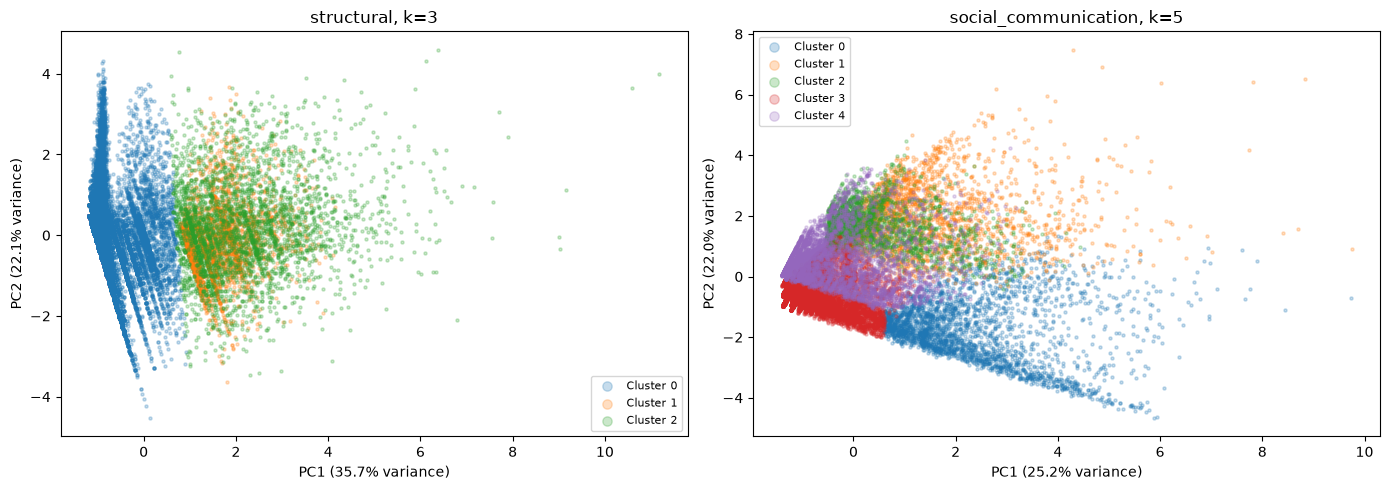

In [16]:
import matplotlib.pyplot as plt

figure_dir = ROOT / "outputs" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

plot_candidates = [
    ("structural", 3),
    ("social_communication", 5),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
coordinate_tables = []

for ax, (representation, k) in zip(axes, plot_candidates):
    coordinates = pca_coordinates[representation]
    labels = candidate_labels[(representation, k)]
    variance_ratio = pca_models[representation].explained_variance_ratio_

    for cluster_id in sorted(np.unique(labels)):
        mask = labels == cluster_id

        ax.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            s=5,
            alpha=0.25,
            label=f"Cluster {cluster_id}",
            rasterized=True,
        )

    ax.set_xlabel(f"PC1 ({variance_ratio[0]:.1%} variance)")
    ax.set_ylabel(f"PC2 ({variance_ratio[1]:.1%} variance)")
    ax.set_title(f"{representation}, k={k}")
    ax.legend(markerscale=3, fontsize=8)

    coordinate_tables.append(pd.DataFrame({
        "episode_id": eligible["episode_id"].to_numpy(),
        "representation": representation,
        "k": k,
        "cluster_id": labels,
        "PC1": coordinates[:, 0],
        "PC2": coordinates[:, 1],
    }))

fig.tight_layout()
fig.savefig(
    figure_dir / "cluster_pca_candidates.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

pd.concat(coordinate_tables, ignore_index=True).to_csv(
    table_dir / "cluster_pca_coordinates.csv",
    index=False,
)

## Feature sensitivity

The sensitivity analysis tests removal of gap fraction and replacement of raw communication counts with events per possible member pair. Pair-normalized counts can exceed one and are not probabilities. Their denominator uses the membership union, so normalization is approximate and does not eliminate every form of size dependence.


In [17]:
# Normalize by all possible pairs in the episode membership union.
possible_pairs = (
    eligible["n_unique_participants"]
    * (eligible["n_unique_participants"] - 1)
    / 2
)

assert (possible_pairs > 0).all()

for prefix in ["calls", "sms"]:
    eligible[f"{prefix}_events_per_pair_pre"] = (
        eligible[f"{prefix}_events_pre"] / possible_pairs
    )

    eligible[f"log_{prefix}_events_per_pair_pre"] = np.log1p(
        eligible[f"{prefix}_events_per_pair_pre"]
    )

normalized_social_columns = [
    "log_median_size",
    "log_span_minutes",
    "gap_fraction",
    "membership_expansion_ratio",
    "median_rssi",
    "internal_fb_density",
    "log_calls_events_per_pair_pre",
    "log_sms_events_per_pair_pre",
]

sensitivity_specs = [
    {
        "name": "structural_without_gap",
        "reference": "structural",
        "k": 3,
        "columns": [
            column for column in used_columns["structural"]
            if column != "gap_fraction"
        ],
    },
    {
        "name": "social_without_gap",
        "reference": "social_communication",
        "k": 5,
        "columns": [
            column for column in used_columns["social_communication"]
            if column != "gap_fraction"
        ],
    },
    {
        "name": "social_pair_normalized",
        "reference": "social_communication",
        "k": 5,
        "columns": normalized_social_columns,
    },
    {
        "name": "social_pair_normalized_without_gap",
        "reference": "social_communication",
        "k": 5,
        "columns": [
            column for column in normalized_social_columns
            if column != "gap_fraction"
        ],
    },
]

## Comparing alternative representations

The analysis compares the new partitions with their references using adjusted Rand index and inspect their profiles. This tests sensitivity to feature choices, not initialization. Removing gap fraction does not remove all extraction effects because span still includes gaps.


In [18]:
sensitivity_rows = []
sensitivity_labels = {}
sensitivity_profile_tables = []

for specification in sensitivity_specs:
    name = specification["name"]
    reference = specification["reference"]
    k = specification["k"]

    X = eligible[specification["columns"]].astype(float)
    assert np.isfinite(X.to_numpy()).all()

    X = X.loc[:, X.nunique() > 1]
    X_scaled = StandardScaler().fit_transform(X)

    model = KMeans(
        n_clusters=k,
        n_init=settings["n_init"],
        random_state=settings["random_seed"],
    )
    labels = model.fit_predict(X_scaled)
    sensitivity_labels[name] = labels

    reference_labels = candidate_labels[(reference, k)]
    sizes = pd.Series(labels).value_counts()

    sensitivity_rows.append({
        "variant": name,
        "reference": reference,
        "k": k,
        "silhouette_sampled": silhouette_score(
            X_scaled,
            labels,
            sample_size=min(
                settings["silhouette_sample_size"],
                len(X_scaled),
            ),
            random_state=settings["random_seed"],
        ),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels),
        "ari_vs_reference": adjusted_rand_score(
            reference_labels, labels
        ),
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
    })

    labelled = eligible.assign(cluster_id=labels)

    columns_to_profile = profile_columns + [
        "calls_events_per_pair_pre",
        "sms_events_per_pair_pre",
    ]

    profiles = labelled.groupby("cluster_id")[columns_to_profile].median()
    profiles.insert(
        0, "n_episodes", labelled.groupby("cluster_id").size()
    )

    print(f"\n{name}")
    print(profiles.round(4).to_string())

    saved_profiles = profiles.reset_index()
    saved_profiles["variant"] = name
    sensitivity_profile_tables.append(saved_profiles)

sensitivity_results = pd.DataFrame(sensitivity_rows)

sensitivity_results.to_csv(
    table_dir / "cluster_feature_sensitivity.csv",
    index=False,
)

pd.concat(sensitivity_profile_tables, ignore_index=True).to_csv(
    table_dir / "cluster_feature_sensitivity_profiles.csv",
    index=False,
)

print("\nFeature sensitivity results:")
print(sensitivity_results.round(4).to_string(index=False))


structural_without_gap
            n_episodes  median_size  span_minutes  gap_fraction  membership_expansion_ratio  median_rssi  internal_fb_density  calls_events_pre  sms_events_pre  calls_events_per_pair_pre  sms_events_per_pair_pre
cluster_id                                                                                                                                                                                                         
0                 3698          4.0          60.0        0.0303                         1.3       -80.75               0.2000               0.0             0.0                        0.0                    0.000
1                15412          3.0           5.0        0.0000                         1.0       -82.00               0.3000               0.0             0.0                        0.0                    0.000
2                 3149         17.0           5.0        0.0000                         1.0       -82.75               0.0952   

## Normalized cluster-count comparison

The analysis evaluates the pair-normalized representation without gap fraction across the same cluster-count range. The analysis does not assume that five clusters remain preferable just because the earlier profiles were interpretable.


In [19]:
# Evaluate the normalized, no-gap representation on the same episodes.
selected_specification = next(
    specification
    for specification in sensitivity_specs
    if specification["name"] == "social_pair_normalized_without_gap"
)

normalized_columns = selected_specification["columns"]

X_normalized = eligible[normalized_columns].astype(float)
assert np.isfinite(X_normalized.to_numpy()).all()

X_normalized = X_normalized.loc[:, X_normalized.nunique() > 1]

normalized_scaler = StandardScaler()
X_normalized_scaled = normalized_scaler.fit_transform(X_normalized)

normalized_models = {}
normalized_labels = {}
normalized_results = []

for k in settings["k_values"]:
    model = KMeans(
        n_clusters=k,
        n_init=settings["n_init"],
        random_state=settings["random_seed"],
    )

    labels = model.fit_predict(X_normalized_scaled)
    sizes = pd.Series(labels).value_counts()

    if len(sizes) < 2:
        continue

    normalized_models[k] = model
    normalized_labels[k] = labels

    normalized_results.append({
        "representation": "social_pair_normalized_without_gap",
        "k": k,
        "silhouette_sampled": silhouette_score(
            X_normalized_scaled,
            labels,
            sample_size=min(
                settings["silhouette_sample_size"],
                len(X_normalized_scaled),
            ),
            random_state=settings["random_seed"],
        ),
        "davies_bouldin": davies_bouldin_score(
            X_normalized_scaled, labels
        ),
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
        "n_episodes": len(labels),
        "random_seed": settings["random_seed"],
        "n_init": settings["n_init"],
    })

normalized_validity = pd.DataFrame(normalized_results)

normalized_validity.to_csv(
    table_dir / "cluster_validity_normalized_without_gap.csv",
    index=False,
)

print(normalized_validity.round(4).to_string(index=False))

                    representation  k  silhouette_sampled  davies_bouldin  smallest_cluster  largest_cluster  n_episodes  random_seed  n_init
social_pair_normalized_without_gap  2              0.4554          1.3841              1853            20406       22259           42      20
social_pair_normalized_without_gap  3              0.3295          1.3626              1682            16666       22259           42      20
social_pair_normalized_without_gap  4              0.2425          1.4193              1379            12044       22259           42      20
social_pair_normalized_without_gap  5              0.2645          1.2906              1347             9938       22259           42      20
social_pair_normalized_without_gap  6              0.2719          1.2641               694             9610       22259           42      20
social_pair_normalized_without_gap  7              0.2614          1.2339               686             8310       22259           42      20
social

## Normalized initialization stability

The stability check repeats the five-cluster fit with several seeds on identical data. Agreement measures initialization stability only; it does not establish robustness to new samples, different extraction settings, or alternative representations.


In [20]:
normalized_seed_labels = {}

for seed in seeds:
    model = KMeans(
        n_clusters=descriptive_k,
        n_init=settings["n_init"],
        random_state=seed,
    )
    normalized_seed_labels[seed] = model.fit_predict(X_normalized_scaled)

normalized_stability_rows = []

for seed_a, seed_b in combinations(seeds, 2):
    normalized_stability_rows.append({
        "representation": "social_pair_normalized_without_gap",
        "k": descriptive_k,
        "seed_a": seed_a,
        "seed_b": seed_b,
        "adjusted_rand_index": adjusted_rand_score(
            normalized_seed_labels[seed_a],
            normalized_seed_labels[seed_b],
        ),
    })

normalized_stability = pd.DataFrame(normalized_stability_rows)

normalized_stability.to_csv(
    table_dir / "cluster_seed_stability_normalized_without_gap.csv",
    index=False,
)

print(
    normalized_stability["adjusted_rand_index"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
    .to_string()
)


mean    0.9993
std     0.0004
min     0.9987
max     0.9998


## Model-selection comparison

The analysis examines two, five, and six clusters before fixing the outputs. The two-cluster solution has the highest sampled silhouette. Five clusters give a more detailed descriptive summary; six mainly add distinctions between call-heavy and SMS-heavy profiles. The analysis retains two clusters as the coarse metric-selected partition and five as an exploratory profile solution, not as a uniquely optimal answer.


In [21]:
# Compare the coarse solution, the descriptive solution,
# and its nearest higher-k alternative.
comparison_profile_columns = [
    "median_size",
    "span_minutes",
    "gap_fraction",
    "membership_expansion_ratio",
    "median_rssi",
    "internal_fb_density",
    "calls_events_per_pair_pre",
    "sms_events_per_pair_pre",
]

final_comparison_tables = []

comparison_k_values = list(dict.fromkeys(
    [coarse_k, descriptive_k] + [k for k in [descriptive_k + 1] if k in normalized_labels]
))
for k in comparison_k_values:
    labelled = eligible.assign(cluster_id=normalized_labels[k])

    profiles = (
        labelled.groupby("cluster_id")[comparison_profile_columns]
        .median()
    )

    sizes = labelled.groupby("cluster_id").size()
    profiles.insert(0, "n_episodes", sizes)
    profiles.insert(1, "share", sizes / len(labelled))

    print(f"\n{'=' * 80}")
    print(f"Normalized social features without gap_fraction, k={k}")
    print(profiles.round(4).to_string())

    saved_profiles = profiles.reset_index()
    saved_profiles["k"] = k
    final_comparison_tables.append(saved_profiles)

pd.concat(final_comparison_tables, ignore_index=True).to_csv(
    table_dir / "cluster_profiles_normalized_final_candidates.csv",
    index=False,
)


Normalized social features without gap_fraction, k=2
            n_episodes   share  median_size  span_minutes  gap_fraction  membership_expansion_ratio  median_rssi  internal_fb_density  calls_events_per_pair_pre  sms_events_per_pair_pre
cluster_id                                                                                                                                                                               
0                20406  0.9168          4.0           5.0           0.0                         1.0        -82.0               0.1667                     0.0000                   0.0000
1                 1853  0.0832          3.0          10.0           0.0                         1.0        -79.0               0.4000                     0.3333                   2.1667

Normalized social features without gap_fraction, k=5
            n_episodes   share  median_size  span_minutes  gap_fraction  membership_expansion_ratio  median_rssi  internal_fb_density  calls_events_

## Final feature-table export

The implementation calculates pair-normalized features for every episode before updating the saved table. This ensures the exported feature table contains the columns used by the selected models. Early episodes remain in the table with their history-availability flag.


In [22]:
# Save the normalized features for every episode, including early episodes.
possible_pairs_all = (
    features["n_unique_participants"]
    * (features["n_unique_participants"] - 1)
    / 2
)

assert (possible_pairs_all > 0).all()

features["n_possible_member_pairs"] = possible_pairs_all.astype(int)

for prefix in ["calls", "sms"]:
    features[f"{prefix}_events_per_pair_pre"] = (
        features[f"{prefix}_events_pre"] / possible_pairs_all
    )

    features[f"log_{prefix}_events_per_pair_pre"] = np.log1p(
        features[f"{prefix}_events_per_pair_pre"]
    )

features["feature_version"] = "pair_normalized_v1"

assert np.isfinite(
    features[X_normalized.columns].to_numpy(dtype=float)
).all()

features.to_parquet(
    processed_dir / "gathering_features_v1.parquet",
    index=False,
)

print("Updated feature table:", features.shape)

Updated feature table: (22530, 46)


## Cluster assignments

The notebook exports both independently fitted partitions. They are not a hierarchy. Episodes with incomplete communication history remain unassigned. Cluster descriptions apply to this particular fitted model; cluster numbers themselves have no semantic meaning.

Only numeric, fit-specific IDs are exported; both partitions are explicitly marked as exploratory. Reported profile descriptions refer to seed 42.


In [23]:
# Retain the existing fitted models; do not refit during export.
coarse_labels = normalized_labels[coarse_k]
detailed_labels = normalized_labels[descriptive_k]

# IDs are fit-specific; semantic descriptions are not exported.
eligible_assignments = pd.DataFrame({
    "episode_id": eligible["episode_id"].to_numpy(),
    "cluster_id": detailed_labels,
    "coarse_cluster_id": coarse_labels,
})


assignments = features[
    ["episode_id", "has_full_communication_window"]
].merge(
    eligible_assignments,
    on="episode_id",
    how="left",
    validate="one_to_one",
)

for column in ["cluster_id", "coarse_cluster_id"]:
    assignments[column] = assignments[column].astype("Int64")

assignments["assignment_status"] = np.where(
    assignments["has_full_communication_window"],
    "assigned",
    "unassigned_incomplete_communication_history",
)

assignments["representation"] = "social_pair_normalized_without_gap"
assignments["input_version"] = "episodes_v1"
assignments["feature_version"] = "pair_normalized_v1"
assignments["random_seed"] = settings["random_seed"]
assignments["coarse_k"] = coarse_k
assignments["descriptive_k"] = descriptive_k
assignments["interpretation"] = "exploratory_representation_dependent"

assert len(assignments) == len(features)
assert assignments["episode_id"].is_unique
assert assignments["cluster_id"].notna().sum() == len(eligible)

assignments.to_csv(
    table_dir / "gathering_clusters.csv",
    index=False,
)

print(assignments["assignment_status"].value_counts().to_string())

assignment_status
assigned                                       22259
unassigned_incomplete_communication_history      271


## Models and analytical metadata

The notebook saves the fitted scaler, both models, feature order, parameters, and software version. The selection rationale distinguishes the silhouette-selected coarse partition from the interpretability-based exploratory partition.


In [24]:
import json
import joblib
import sklearn

model_dir = ROOT / "outputs" / "models"
model_dir.mkdir(parents=True, exist_ok=True)

metadata = {
    "representation": "social_pair_normalized_without_gap",
    "feature_columns": X_normalized.columns.tolist(),
    "input_version": "episodes_v1",
    "feature_version": "pair_normalized_v1",
    "random_seed": settings["random_seed"],
    "n_init": settings["n_init"],
    "communication_lookback_hours": lookback_hours,
    "n_fitted_episodes": len(eligible),
    "coarse_k": coarse_k,
    "descriptive_k": descriptive_k,
    "selection_reason": (
        f"Configured coarse partition: k={coarse_k}; "
        f"configured exploratory partition: k={descriptive_k}. "
        "In the reviewed seed-42 run, k=2 maximized sampled silhouette "
        "and k=5 was retained for descriptive interpretation."
    ),
    "time_origin_verified": False,
    "sklearn_version": sklearn.__version__,
}

joblib.dump(
    {
        "scaler": normalized_scaler,
        "coarse_model": normalized_models[coarse_k],
        "descriptive_model": normalized_models[descriptive_k],
        "metadata": metadata,
    },
    model_dir / "gathering_clustering_v1.joblib",
)

with (model_dir / "gathering_clustering_v1_metadata.json").open("w") as file:
    json.dump(metadata, file, indent=2)

print("Saved clustering models and metadata.")

Saved clustering models and metadata.


## Final PCA visualization

PCA is recomputed for the selected seven-feature representation. In the reported run, two components retain 50.46% of variance and six retain 94.25%. The analysis uses the two-dimensional projection only to illustrate the full-space assignments; visual overlap is not sufficient to judge separation in all seven dimensions.


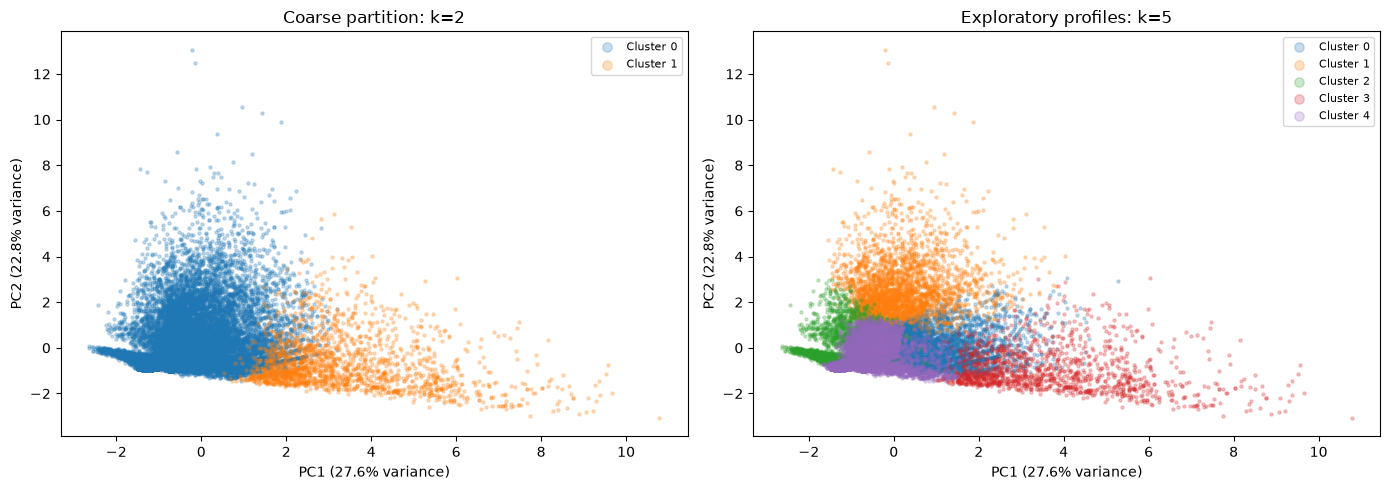

 component  explained_variance_ratio  cumulative_variance
         1                    0.2761               0.2761
         2                    0.2285               0.5046
         3                    0.1474               0.6520
         4                    0.1241               0.7761
         5                    0.0902               0.8663
         6                    0.0763               0.9425
         7                    0.0575               1.0000


In [25]:
# Visualize the full-space clustering without changing its assignments.
final_pca = PCA(svd_solver="full")
final_coordinates = final_pca.fit_transform(X_normalized_scaled)

variance_ratio = final_pca.explained_variance_ratio_

variance_table = pd.DataFrame({
    "component": np.arange(1, len(variance_ratio) + 1),
    "explained_variance_ratio": variance_ratio,
    "cumulative_variance": np.cumsum(variance_ratio),
})

variance_table.to_csv(
    table_dir / "pca_selected_representation.csv",
    index=False,
)

coordinates_table = pd.DataFrame({
    "episode_id": eligible["episode_id"].to_numpy(),
    "PC1": final_coordinates[:, 0],
    "PC2": final_coordinates[:, 1],
    "cluster_id": detailed_labels,
    "coarse_cluster_id": coarse_labels,
})

coordinates_table.to_csv(
    table_dir / "cluster_visualization_coordinates.csv",
    index=False,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, labels, title in [
    (axes[0], coarse_labels, f"Coarse partition: k={coarse_k}"),
    (axes[1], detailed_labels, f"Exploratory profiles: k={descriptive_k}"),
]:
    for cluster_id in sorted(np.unique(labels)):
        mask = labels == cluster_id
        ax.scatter(
            final_coordinates[mask, 0],
            final_coordinates[mask, 1],
            s=5,
            alpha=0.25,
            label=f"Cluster {cluster_id}",
            rasterized=True,
        )

    ax.set_xlabel(f"PC1 ({variance_ratio[0]:.1%} variance)")
    ax.set_ylabel(f"PC2 ({variance_ratio[1]:.1%} variance)")
    ax.set_title(title)
    ax.legend(markerscale=3, fontsize=8)

fig.tight_layout()
fig.savefig(
    figure_dir / "cluster_visualization.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print(variance_table.round(4).to_string(index=False))

## Saved-artifact checks

The verification reloads the exported files and check that saved model predictions match the recorded assignments. This verifies artifact consistency, not a clean-kernel rerun or reproducibility on another machine.


In [26]:
# Verify the saved artifacts rather than relying on notebook state.
saved_features = pd.read_parquet(
    processed_dir / "gathering_features_v1.parquet"
)

saved_assignments = pd.read_csv(
    table_dir / "gathering_clusters.csv"
)

saved_bundle = joblib.load(
    model_dir / "gathering_clustering_v1.joblib"
)

assert saved_features["episode_id"].is_unique
assert saved_assignments["episode_id"].is_unique
assert len(saved_features) == len(saved_assignments)

# Preserve the same episode order when checking model predictions.
saved_eligible = saved_features.loc[
    saved_features["has_full_communication_window"]
].copy()

columns = saved_bundle["metadata"]["feature_columns"]

saved_X_scaled = saved_bundle["scaler"].transform(
    saved_eligible[columns].astype(float)
)

predicted_detailed = saved_bundle["descriptive_model"].predict(
    saved_X_scaled
)
predicted_coarse = saved_bundle["coarse_model"].predict(
    saved_X_scaled
)

indexed_assignments = saved_assignments.set_index("episode_id")
aligned = indexed_assignments.loc[
    saved_eligible["episode_id"].to_numpy()
]

assert np.array_equal(
    predicted_detailed,
    aligned["cluster_id"].to_numpy(dtype=int),
)
assert np.array_equal(
    predicted_coarse,
    aligned["coarse_cluster_id"].to_numpy(dtype=int),
)

excluded = saved_assignments.loc[
    saved_assignments["assignment_status"]
    == "unassigned_incomplete_communication_history"
]

assert excluded[["cluster_id", "coarse_cluster_id"]].isna().all().all()

print("Saved artifacts verified.")
print("Total episodes:", len(saved_features))
print("Assigned episodes:", len(saved_eligible))
print("Unassigned episodes:", len(excluded))
print("Model features:", columns)

Saved artifacts verified.
Total episodes: 22530
Assigned episodes: 22259
Unassigned episodes: 271
Model features: ['log_median_size', 'log_span_minutes', 'membership_expansion_ratio', 'median_rssi', 'internal_fb_density', 'log_calls_events_per_pair_pre', 'log_sms_events_per_pair_pre']


## Findings and limitations

In the previously reported run, 22,259 of 22,530 episodes had a complete 24-hour communication window. The remaining 271 were retained in the feature table but left unassigned.

The pair-normalized, no-gap representation achieved its highest sampled silhouette at two clusters (0.4554), with cluster sizes of 20,406 and 1,853 episodes (91.7% and 8.3%). This silhouette therefore describes a strongly imbalanced partition. A five-cluster exploratory solution was also retained (silhouette 0.2645), whose mean initialization ARI was 0.9993. These are reported results from the earlier run, not fresh execution results of this edited copy.

The five profiles describe smaller higher-friendship/stronger-signal episodes, longer spans with expanded membership, larger short spans, higher prior communication per pair, and smaller lower-friendship/weaker-signal episodes. These descriptions belong to the reviewed seed-42 fit and are exploratory, not verified social categories. Numeric cluster IDs may change with seed or software version. Semantic descriptions are omitted from the assignment export.

Feature changes materially altered the partitions despite high seed agreement. Feature-robust archetypes are therefore not claimed. Missing scans and linking parameters can affect span and membership expansion; membership unions need not represent simultaneous attendance. Facebook data are retrospective, communication normalization is approximate, and clock-time origin remains unverified.

## Execution status

Saved-artifact checks are included above. A successful artifact check does not replace restarting the kernel and running every cell in order. This editorial revision preserves the code logic and does not certify an unperformed end-to-end rerun.
